In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [2]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [4]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                               final  \
0  đánh giá: xuất_sắc ưu điểm: tốt về chất_lượng ...   
1  đánh giá: tiếc là đi vào ngày trời âm_u biển đ...   
2  đánh giá: xuất_sắc ưu điểm: phòng_ốc sạch_sẽ t...   
3  đánh giá: xuất_sắc ưu điểm: phòng sạch_sẽ gần ...   
4  đánh giá: hài_lòng ưu điểm: đối_diện biển rất ...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [5]:
df.loc[:, 'label'] = df['score'].astype(int)
X = df['final']
y = df['label']

In [6]:
from sklearn.model_selection import train_test_split

# Giả sử docs = df['final'] và labels = df['label']
docs = df['final']
labels = df['score'].astype(int)

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu


In [7]:
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 3), max_features=8000, min_df=3)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        max_features='sqrt',
        class_weight='balanced_subsample',   # cân bằng ở mỗi bootstrap sample
        random_state=42,
        n_jobs=-1
    ))
])

In [8]:
best_score = 0
best_params = {}

# Danh sách các tổ hợp tham số muốn thử (có thể mở rộng thêm)
param_grid = [
    {'n_estimators': 100, 'max_depth': None, 'min_samples_split': 2},
    {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 2},
    {'n_estimators': 200, 'max_depth': 30,   'min_samples_split': 5},
    {'n_estimators': 300, 'max_depth': 20,   'min_samples_split': 5},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 10},
]

for params in param_grid:
    # Cập nhật tất cả tham số cho bước 'rf' trong pipeline
    model_pipeline.set_params(**{f"rf__{k}": v for k, v in params.items()})

    # Huấn luyện
    model_pipeline.fit(X_train, y_train)

    # Đánh giá
    val_score = model_pipeline.score(X_val, y_val)
    print(f"Params: {params} => Validation Accuracy: {val_score:.4f}")

    if val_score > best_score:
        best_score = val_score
        best_params = params

print(f"---")
print(f"Tham số tốt nhất tìm được:")
for k, v in best_params.items():
    print(f"  {k:>18}: {v}")
print(f"  Best Validation Accuracy: {best_score:.4f}")

# Áp dụng tham số tốt nhất và train lại
model_pipeline.set_params(**{f"rf__{k}": v for k, v in best_params.items()})
model_pipeline.fit(X_train, y_train)  # Có thể dùng X_train + X_val để tăng dữ liệu

print(f"Final Test Accuracy: {model_pipeline.score(X_test, y_test):.4f}")

Params: {'n_estimators': 100, 'max_depth': None, 'min_samples_split': 2} => Validation Accuracy: 0.8118
Params: {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 2} => Validation Accuracy: 0.8126
Params: {'n_estimators': 200, 'max_depth': 30, 'min_samples_split': 5} => Validation Accuracy: 0.8005
Params: {'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 5} => Validation Accuracy: 0.7902
Params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 10} => Validation Accuracy: 0.8147
---
Tham số tốt nhất tìm được:
        n_estimators: 300
           max_depth: None
   min_samples_split: 10
  Best Validation Accuracy: 0.8147
Final Test Accuracy: 0.8015


In [9]:
y_pred = model_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           5       0.71      0.69      0.70       194
           6       0.84      0.54      0.66       212
           7       0.49      0.70      0.57       483
           8       0.73      0.64      0.68      1107
           9       0.85      0.61      0.71      1712
          10       0.85      0.94      0.89      4520

    accuracy                           0.80      8228
   macro avg       0.74      0.69      0.70      8228
weighted avg       0.81      0.80      0.80      8228



In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch
import textwrap   # để in đẹp hơn nếu cần

# ----------------------------------------------------------------------
# Đảm bảo y_test và y_pred ở dạng numpy array (phổ biến nhất)
# ----------------------------------------------------------------------
if isinstance(y_test, torch.Tensor):
    y_test_np    = y_test.cpu().numpy()
else:
    y_test_np    = np.asarray(y_test)

if isinstance(y_pred, torch.Tensor):
    y_pred_np    = y_pred.cpu().numpy()
else:
    y_pred_np    = np.asarray(y_pred)

# Nếu là multi-class và y_pred là probability → lấy argmax
if len(y_pred_np.shape) > 1 and y_pred_np.shape[1] > 1:
    y_pred_np = np.argmax(y_pred_np, axis=1)

# ----------------------------------------------------------------------
# Tính các metric cơ bản
# ----------------------------------------------------------------------
accuracy = accuracy_score(y_test_np, y_pred_np)

# In header
print("\n" + "="*80)
print("              MODEL EVALUATION ON TEST SET")
print("="*80)

# Accuracy chi tiết
print(f"\nOverall Accuracy:")
print(f"  • {accuracy:.4f}  ({accuracy*100:.2f}%)")
print("-"*60)

# Classification Report (chi tiết, 4 chữ số thập phân)
print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred_np,
    digits=4,
    zero_division=0,
    target_names=[str(c) for c in model_pipeline.classes_]   # nếu có class names đẹp
    # target_names = ['Negative', 'Positive']  # → bạn có thể hard-code tên lớp nếu muốn
))

# ----------------------------------------------------------------------
# Confusion Matrix - cả dạng số lượng và dạng chuẩn hóa (%)
# ----------------------------------------------------------------------
cm = confusion_matrix(y_test_np, y_pred_np)

print("\nConfusion Matrix (Raw counts):")
print(cm)

# Chuẩn hóa theo hàng (precision-oriented: tỷ lệ dự đoán đúng trong mỗi lớp thật)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)  # tránh NaN nếu có lớp không có mẫu

# ----------------------------------------------------------------------
# Một số metric tổng hợp bổ sung (macro / weighted)
# ----------------------------------------------------------------------
print("\nSummary Metrics:")
print(f"  Macro    Avg Precision : {precision_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg Recall    : {recall_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg F1-score  : {f1_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Weighted Avg F1-score : {f1_score(y_test_np, y_pred_np, average='weighted', zero_division=0):.4f}")

# Kết thúc đẹp
# ----------------------------------------------------------------------
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*80)
print(f"HOÀN TẤT ĐÁNH GIÁ!  •  Accuracy = {accuracy*100:.2f}%")
print("="*80 + "\n")


              MODEL EVALUATION ON TEST SET

Overall Accuracy:
  • 0.8015  (80.15%)
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           5     0.7074    0.6856    0.6963       194
           6     0.8382    0.5377    0.6552       212
           7     0.4877    0.6998    0.5748       483
           8     0.7298    0.6441    0.6843      1107
           9     0.8528    0.6057    0.7083      1712
          10     0.8489    0.9425    0.8933      4520

    accuracy                         0.8015      8228
   macro avg     0.7442    0.6859    0.7020      8228
weighted avg     0.8089    0.8015    0.7972      8228


Confusion Matrix (Raw counts):
[[ 133    3   20   21    6   11]
 [  20  114   35   21    8   14]
 [  21    6  338   55   20   43]
 [   5    7  101  713   68  213]
 [   6    1   97   94 1037  477]
 [   3    5  102   73   77 4260]]

Summary Metrics:
  Macro    Avg Precision : 0.7442
  Mac

In [11]:
import joblib

# Lưu mô hình vào file
model_filename = '/content/drive/MyDrive/Bert/Model/tf-idf-rf/randomforest_tfidf_sentiment_model.pkl'
joblib.dump(model_pipeline, model_filename)

print(f"Mô hình đã được lưu tại: {model_filename}")

Mô hình đã được lưu tại: /content/drive/MyDrive/Bert/Model/tf-idf-rf/randomforest_tfidf_sentiment_model.pkl


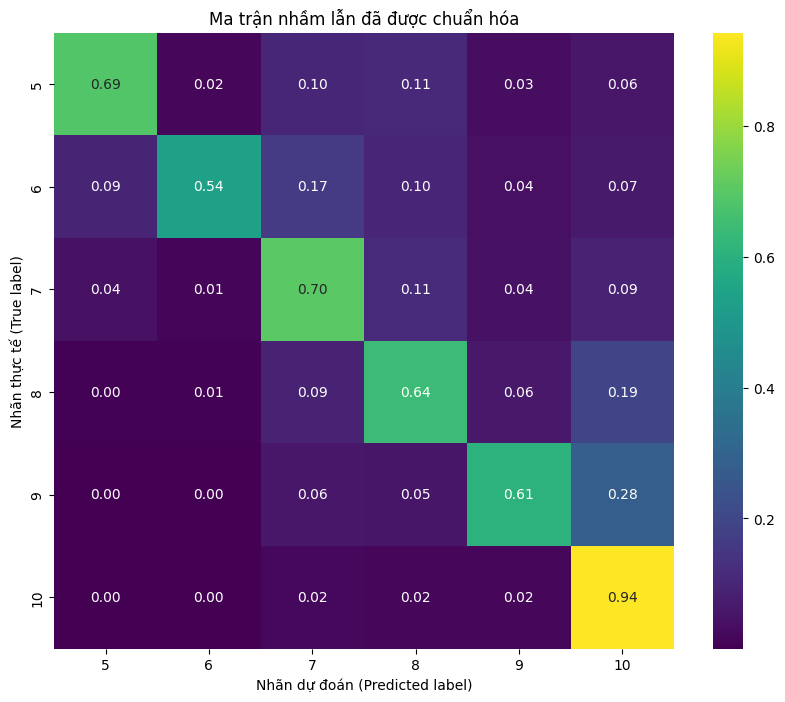

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns   # chỉ cần nếu bạn muốn dùng seaborn ở phần sau


y_pred = model_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Lấy tên các lớp dựa trên điểm rating thực tế
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='viridis',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn đã được chuẩn hóa')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()


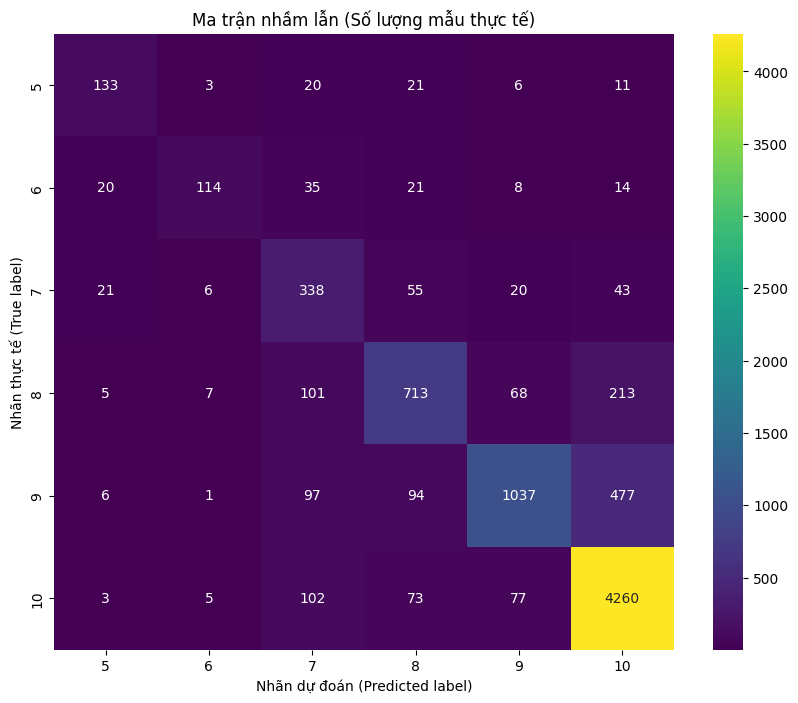

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính ma trận nhầm lẫn (đây là dạng số lượng gốc)
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
# 2. Tên các lớp (từ 5 đến 10)
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))

# 3. Vẽ Heatmap với biến 'cm' gốc
sns.heatmap(
    cm,
    annot=True,      # Hiển thị số lên ô
    fmt='d',         # ĐỊNH DẠNG LÀ SỐ NGUYÊN (d = decimal/integer)
    cmap='viridis',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Ma trận nhầm lẫn (Số lượng mẫu thực tế)')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()